# 02 Exploratory data analysis

This notebook explores the clean dataset from `01_preprocessing.ipynb`, which is the exact data all models use. It has 5,000 randomly sampled users, their full anime lists and the catalog of 6,668 anime.

The data is stored in the repository in `data/processed`, so it is available after a git pull.

**What this notebook covers**

1. Feedback, the long tail and sparsity
2. The definition of a relevant anime, used by every model
3. Time as context
4. The anime and their text
5. The users and whether their tastes differ by group
6. What this means for the business

In [1]:
%pip install -q pandas pyarrow matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set a concrete seed to make results reproducible
import random
my_seed = 1234
random.seed(my_seed)
np.random.seed(my_seed)

In [3]:
interactions_df = pd.read_parquet("../data/processed/interactions.parquet")
users_df = pd.read_parquet("../data/processed/users.parquet")
anime_df = pd.read_parquet("../data/processed/anime.parquet")

print("interactions:", interactions_df.shape)
print("users:", users_df.shape)
print("anime:", anime_df.shape)

interactions: (1539231, 6)
users: (5000, 6)
anime: (6668, 15)


**About the data**

- `interactions_df` has one row per user and anime. A row is an explicit rating when `score` is above 0. Rows with score 0 are implicit feedback, where the user added the anime to their list without rating it.
- `status` is 1 watching, 2 completed, 3 on hold, 4 dropped and 6 plan to watch.
- `users_df` and `anime_df` link to the interactions through `user_id` and `anime_id`.
- `last_updated` is when the user last changed the entry, not when they watched the anime.

## 1. Feedback
### Explicit and implicit feedback

In [4]:
status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}

status_share = interactions_df["status"].map(status_names).value_counts(normalize=True)
print(status_share.round(3))
print()
print(f"Share of interactions with a score: {(interactions_df['score'] > 0).mean():.3f}")

status
completed        0.637
plan to watch    0.237
watching         0.049
dropped          0.040
on hold          0.037
Name: proportion, dtype: float64

Share of interactions with a score: 0.635


**Every user has both explicit and implicit feedback.** 64% of the entries are completed anime and 24% are plan to watch, and 63.5% of all entries have a score. The score is explicit feedback, a clear opinion but one that needs effort from the user. The status is implicit feedback, which is more abundant but harder to interpret [5, p. 10]. Having both means the project can build and evaluate recommenders on each type, which is one of the advanced criteria in the course [11, p. 2]. How the status is turned into a 0 or 1 label is decided and justified in Part 1.2 of 03_recommenders.

One could argue that only the scores are needed, since they are the clearer signal. But 36.5% of the entries have no score, and most of them are plan to watch entries that show what users want next. Ignoring them would throw away a third of the behaviour in the data.

### Ratings

There are 977062 ratings from 5000 users to 6037 anime
Mean rating: 7.56
Median rating: 8


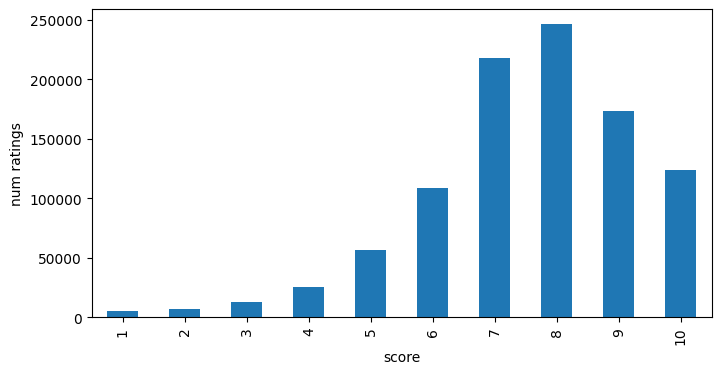

In [5]:
ratings_df = interactions_df[interactions_df["score"] > 0]

def basic_stats(df, user_col, item_col):
    n_rows = df.shape[0]
    n_users = df[user_col].nunique()
    n_items = df[item_col].nunique()
    print(f"There are {n_rows} ratings from {n_users} users to {n_items} anime")
    return n_rows, n_users, n_items

n_ratings, n_users, n_items = basic_stats(ratings_df, "user_id", "anime_id")
print(f"Mean rating: {ratings_df['score'].mean():.2f}")
print(f"Median rating: {ratings_df['score'].median():.0f}")

plt.figure(figsize=(8, 4))
ratings_df.groupby("score").size().plot.bar();
plt.ylabel("num ratings");

**The ratings are strongly positive, and this affects how every model must be evaluated.** The mean rating is 7.56 and the median is 8, while scores from 1 to 4 make up only 5.1% of all ratings.

The main reason is selection. Users choose what to watch and mostly pick anime they expect to like, so the ratings that would exist for randomly chosen anime are largely missing [3, p. 109]. The consequence for evaluation is that even a random ranking puts mostly well-rated anime near the top, and the difference between an 8 and a 9 barely moves NDCG [10, p. 17]. Ranking metrics therefore have to be read against the random baseline, never on their own. For prediction, it means most of the information lies between 7 and 9, so an RMSE close to 1 is already a meaningful error on this scale.

An alternative explanation is that MyAnimeList users are simply generous. That cannot be separated from selection with this data, but both explanations lead to the same consequence for evaluation. Users do discriminate between anime, since the average per anime ranges from 1.0 to 10.0, so the scores still carry information.

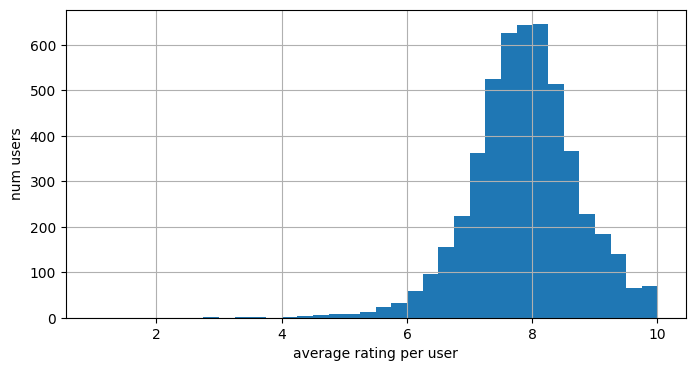

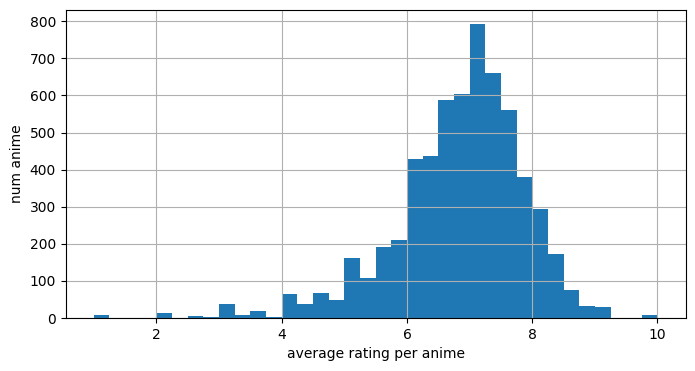

In [6]:
plt.figure(figsize=(8, 4))
ratings_df.groupby("user_id")["score"].mean().hist(bins=np.arange(1, 10.25, 0.25));
plt.xlabel("average rating per user");
plt.ylabel("num users");

plt.figure(figsize=(8, 4))
ratings_df.groupby("anime_id")["score"].mean().hist(bins=np.arange(1, 10.25, 0.25));
plt.xlabel("average rating per anime");
plt.ylabel("num anime");

**Users differ in how generous they are, and anime with few ratings have unreliable averages.** Half of the users have an average between 7.38 and 8.39, but 135 users average 9.5 or more and 101 average 6 or less. A 7 from a generous user means something different from a 7 from a strict one. Much of the variation in ratings is explained by these user and item biases rather than by personal taste, and models such as SVD estimate them explicitly [3, p. 109]. This is one reason SVD is expected to beat a plain popularity ranking.

The averages per anime have a long left side. Anime with fewer than 10 ratings average 5.99 with a spread of 1.43, while anime with at least 500 ratings average 7.85 with a spread of only 0.53. An average from a few users depends heavily on who those users are. A popularity recommender that ranks anime by their plain average will therefore be pulled towards anime with very few ratings, which is why the Bayesian average is tested in Part 2 [11, p. 2].

### Long tail and sparsity

The 20% most rated anime have 71.6% of all ratings
Median number of ratings per anime: 53.0
Anime with fewer than 10 ratings: 1190
Anime in the catalog without any rating in the sample: 631


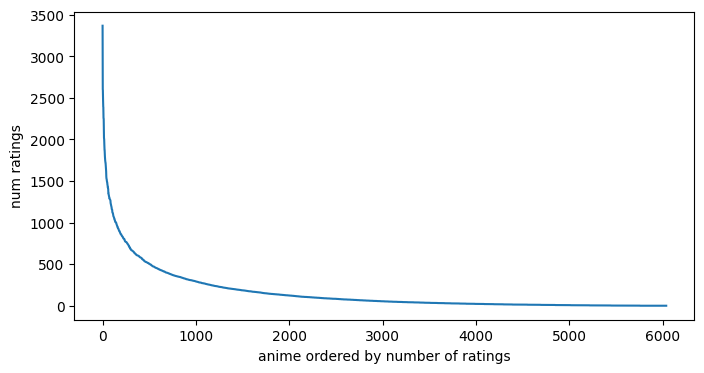

In [7]:
ratings_per_anime = ratings_df.groupby("anime_id").size().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.plot(range(len(ratings_per_anime)), ratings_per_anime.values);
plt.xlabel("anime ordered by number of ratings");
plt.ylabel("num ratings");

top_20_share = ratings_per_anime.iloc[: int(len(ratings_per_anime) * 0.2)].sum() / ratings_per_anime.sum()
print(f"The 20% most rated anime have {top_20_share:.1%} of all ratings")
print("Median number of ratings per anime:", ratings_per_anime.median())
print("Anime with fewer than 10 ratings:", (ratings_per_anime < 10).sum())
print("Anime in the catalog without any rating in the sample:", len(anime_df) - n_items)

**A small part of the catalog receives most of the attention.** The 20% most rated anime receive 71.6% of all ratings, while the median anime has only 53 ratings in the sample. 1,190 anime have fewer than 10 ratings, and 631 anime in the catalog have no rating at all from the sampled users.

This long tail has three consequences [3, pp. 32-33]. Popular anime are easy to recommend but give the user little that is new. Predictions for anime in the tail are harder because there is little data about them. And many algorithms drift towards popular anime, which lowers coverage and diversity. This is why coverage, personalization and diversity are measured next to accuracy in this project. It also means the 631 unrated anime can only be recommended by a content-based model.

One could argue that rarely rated anime are rare because they are less appealing, so pushing them would lower satisfaction. There is a real trade-off between safe recommendations and surprising ones [13, Session 5]. The goal is not to recommend the tail to everyone, but to show each tail anime to the users most likely to enjoy it, which is what personalized models are designed to do.

In [8]:
ratings_per_user = ratings_df.groupby("user_id").size()
print(ratings_per_user.describe().round(0))

sparsity = 1 - n_ratings / (n_users * n_items)
print()
print(f"The user-anime rating matrix is {sparsity:.2%} empty")

count    5000.0
mean      195.0
std       229.0
min        10.0
25%        56.0
50%       124.0
75%       249.0
max      3033.0
dtype: float64

The user-anime rating matrix is 96.76% empty


**The rating matrix is sparse, even after the filtering in 01.** Every sampled user has at least 10 ratings and the median user has 124, yet 96.76% of the user and anime pairs are empty. In typical recommender data around 99% of pairs are unrated [13, Session 6], so this data is somewhat denser because of the minimum of 10 ratings and the small catalog. That helps collaborative filtering. But two users still share few anime on average, which matters for memory-based models. They compare users on the anime both have rated, and similarities based on very few common anime are noisy [13, Session 14]. The minimum number of anime in common (`min_support`) is therefore a key setting to test in Part 3.

## 2. What counts as a relevant anime

Precision, recall, MAP and the bandits need a yes or no answer to the question "did the user like this anime?". This section defines that answer once, so every model in the project is evaluated in the same way.

In [9]:
for threshold in [7, 8, 9]:
    share = (ratings_df["score"] >= threshold).mean()
    print(f"Share of ratings with a score of {threshold} or more: {share:.3f}")

Share of ratings with a score of 7 or more: 0.780
Share of ratings with a score of 8 or more: 0.557
Share of ratings with a score of 9 or more: 0.304


In [10]:
relevant_score = 8

relevant_df = ratings_df[ratings_df["score"] >= relevant_score]
relevant_per_user = relevant_df.groupby("user_id").size().reindex(users_df["user_id"], fill_value=0)

print(relevant_per_user.describe().round(0))
print("Users with no relevant anime:", (relevant_per_user == 0).sum())

count    5000.0
mean      109.0
std       119.0
min         0.0
25%        34.0
50%        71.0
75%       141.0
max      1470.0
dtype: float64
Users with no relevant anime: 1


**A score of 8 or more is the best definition of a relevant anime for this project.** Precision, recall, MAP and the bandits need a yes or no answer to whether a user liked an anime, and that boundary has to be decided explicitly [4, p. 227].

The threshold has to separate liked anime from merely watched ones. Because the ratings are so positive, a low threshold fails to do that. A score of 7 or more would make 78% of all ratings relevant, so even a random list would be mostly relevant and the metrics would no longer separate good models from bad ones [10, p. 17]. A score of 9 or more keeps only 30%, which would count many anime the user clearly liked as failures. A score of 8 is the median rating, so relevant means better than a typical rating for this audience. With this rule the median user has 71 relevant anime and only one user has none, so almost every user can be evaluated.

The strongest alternative is a threshold per user, for example anything above the user's own average, since a relevance boundary can also be defined relative to the user's mean [4, p. 227]. It would correct for the user bias shown above. It was not chosen because the user's average must be computed on the training data only, or it leaks test ratings into the label, and that is easy to get wrong across several parts of the notebook. Every part uses `relevant_score = 8`, and a per-user threshold can be added as a robustness check on the final model.

## 3. Time as context

              mean   count
last_updated              
2006          7.86      85
2007          7.61   11809
2008          7.66   50140
2009          7.71   72030
2010          7.67   77034
2011          7.67   75413
2012          7.63   86744
2013          7.63  108655
2014          7.52  113774
2015          7.54  117089
2016          7.48  120550
2017          7.41  104223
2018          7.30   39516


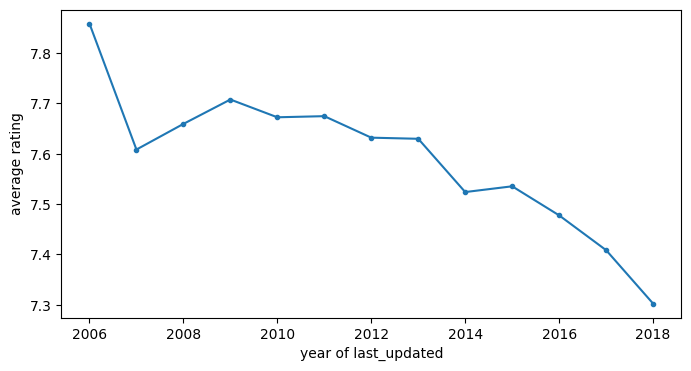

In [11]:
per_year = ratings_df.groupby(ratings_df["last_updated"].dt.year)["score"].agg(["mean", "count"])
print(per_year.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
per_year["mean"].plot(marker=".", ax=ax);
ax.set_xlabel("year of last_updated");
ax.set_ylabel("average rating");

**Ratings fall over time, so the evaluation must include a split by time.** The average rating drops steadily from 7.71 in 2009 to 7.30 in 2018. The data does not show why. It could be a changing audience as the site grew, or users lowering old scores when they edit their lists.

Whatever the cause, a model trained on older ratings will predict too high for recent ones. A random split hides this, because it mixes past and future ratings in training. Cross-validation through time trains on the past and tests on later data, which is how the system would be used in production [7, pp. 26-27]. The trend also makes the year a candidate context for the context-aware models, for example by training on recent data only, which is a form of contextual pre-filtering [8, p. 16].

The counterargument is that 2018 only covers five months and the earliest years have few ratings, so the extremes are less reliable. But the decline is steady across 2012 to 2017, the years with the most ratings, so it is not driven by the edges.

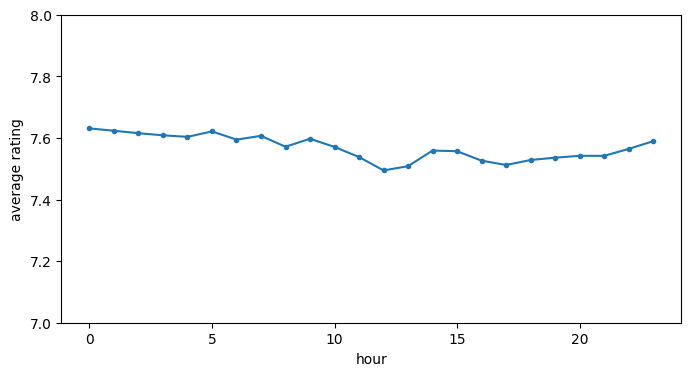

In [12]:
plt.figure(figsize=(8, 4))
ratings_df.groupby(ratings_df["last_updated"].dt.hour)["score"].mean().plot(marker=".");
plt.xlabel("hour");
plt.ylabel("average rating");
plt.ylim(7, 8);

**The hour of the day is not a useful context here.** The average rating barely moves across the day. The time zone of `last_updated` is also unknown, and the users live in many countries. When ratings from different time zones are mixed, the hour no longer reflects the user's local time, which makes time-of-day context unreliable [13, Session 19]. It is therefore left out of the context-aware models.

## 4. The anime

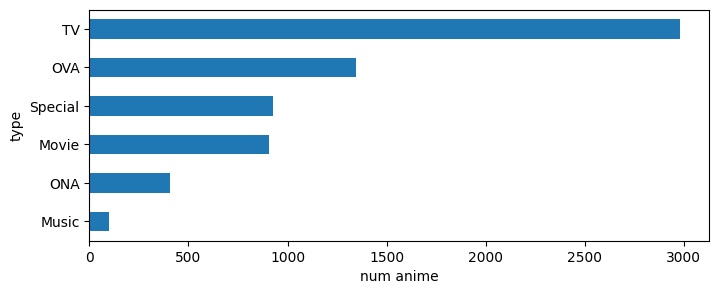

In [13]:
anime_df.groupby("type").size().sort_values().plot.barh(figsize=(8, 3));
plt.xlabel("num anime");

Number of different genres: 43
Average number of genres per anime: 3.6


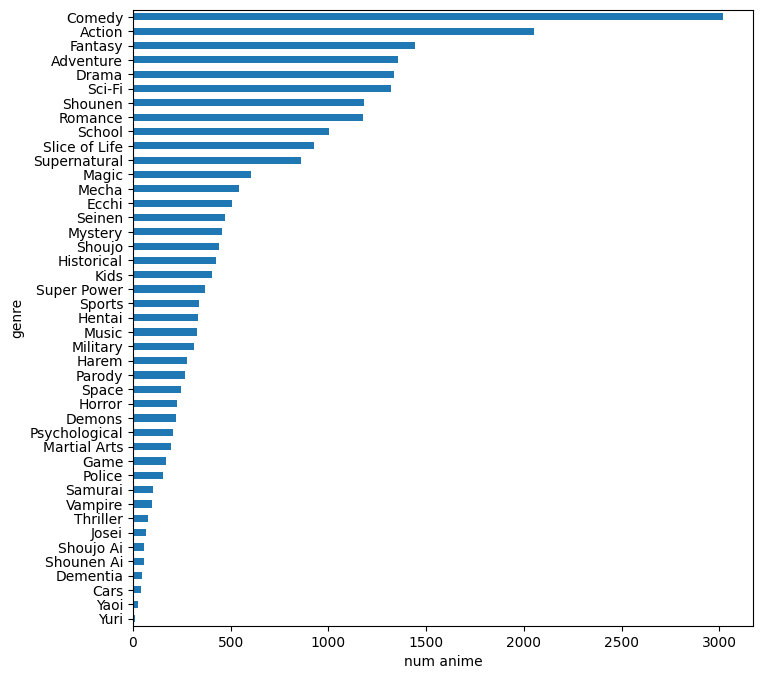

In [14]:
genres = anime_df["genre"].dropna().str.split(", ").explode()

plt.figure(figsize=(8, 8))
genres.value_counts().sort_values().plot.barh();
plt.xlabel("num anime");

print("Number of different genres:", genres.nunique())
print("Average number of genres per anime:", round(anime_df["genre"].dropna().str.split(", ").str.len().mean(), 1))

There are 43 genres and each anime has 3.6 on average. Comedy and Action are the most common. Genres serve two purposes in the project. They are item features for the content-based models, and they are the metadata the diversity metric needs, since intra-list similarity compares the categories of the recommended items [6, pp. 25-27]. TV series are the largest type, followed by OVA, specials and movies.

count    6323.0
mean       88.0
std        62.0
min         2.0
25%        33.0
50%        80.0
75%       137.0
max       487.0
Name: synopsis, dtype: float64
Anime without a synopsis: 345
Synopses with fewer than 20 words: 1105

10    The second part of Junjou Romantica continuing...
12                 Second season of Sekaiichi Hatsukoi.
56    OVA of Diabolik Lovers included with the upcom...
57            Based on the characters created by Study.
59                     Picture dramas from the DVD/BDs.


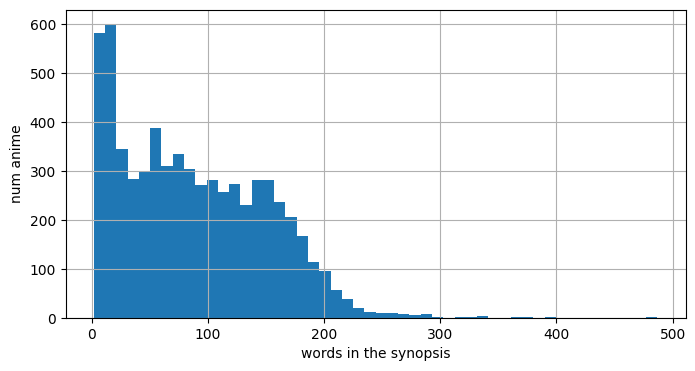

In [15]:
synopsis_words = anime_df["synopsis"].dropna().str.split().str.len()

plt.figure(figsize=(8, 4))
synopsis_words.hist(bins=50);
plt.xlabel("words in the synopsis");
plt.ylabel("num anime");

print(synopsis_words.describe().round(0))
print("Anime without a synopsis:", anime_df["synopsis"].isna().sum())
print("Synopses with fewer than 20 words:", (synopsis_words < 20).sum())
print()
print(anime_df.loc[synopsis_words[synopsis_words < 20].index, "synopsis"].head(5).to_string())

**The synopsis alone is not enough for every anime, so the content-based models should combine it with title and genres.** The median synopsis has 80 words, which is enough for TF-IDF and BERT. But 345 anime have no synopsis and 1,105 synopses have fewer than 20 words. Most of the short ones are sequels or extras described only in relation to another title, like the examples above, so they say almost nothing about the content. Complementing the text with categorical features is the recommended way to strengthen a content-based model [12, p. 1].

One could argue that BERT captures meaning even from short texts. But a sentence like "Second season of Sekaiichi Hatsukoi" contains no information about the story or genre, whatever model reads it. Adding the genres gives every anime a minimum description.

## 5. The users
### Who the users are

In [16]:
print(users_df["gender"].value_counts())
print()
print(users_df["age_group"].value_counts().sort_index())
print()
print(users_df["country"].value_counts().head(10))

gender
Male          3310
Female        1667
Non-Binary      23
Name: count, dtype: int64

age_group
under 18        179
18-22          1328
23-27          2074
28-32          1123
33 and over     296
Name: count, dtype: int64

country
Unknown               1757
United States          758
Brazil                 221
Canada                 192
United Kingdom         184
Poland                 179
Other                  173
Russian Federation     109
Germany                 97
Philippines             94
Name: count, dtype: int64


**The audience is young and mostly male, which matters for fairness.** Two thirds of the sampled users are male, one third female and 23 non-binary. Most are between 18 and 32. Country is Unknown for 35% of the users, and most known countries have fewer than 200 users in the sample.

A recommender trained on this data learns mostly the tastes of young men, and groups with few users get less personal recommendations because there is less data about them. User attributes like age and gender are also personal data, and their use has to respect privacy regulations [13, Session 6]. Both points belong in the ethics discussion of the final system.

### Do tastes differ between groups?

Demographic filtering only makes sense if different groups like different anime. This is checked in two ways. First the average rating per group, then how much the 10 most liked anime of two groups overlap.

In [17]:
ratings_users_df = ratings_df.merge(users_df, on="user_id")

print(ratings_users_df.groupby("gender")["score"].agg(["mean", "count"]).round(2))
print()
print(ratings_users_df.groupby("age_group", observed=True)["score"].agg(["mean", "count"]).round(2))

            mean   count
gender                  
Female      7.69  240460
Male        7.53  728535
Non-Binary  6.84    8067

             mean   count
age_group                
under 18     7.40   26243
18-22        7.60  241451
23-27        7.62  396836
28-32        7.50  242659
33 and over  7.40   69873


In [18]:
def top_anime(df, n=10):
    liked = df[df["score"] >= relevant_score]
    return liked.groupby("anime_id").size().sort_values(ascending=False).index[:n]

def titles(anime_ids):
    return anime_df.set_index("anime_id").loc[list(anime_ids), "title"].tolist()

top_male = top_anime(ratings_users_df[ratings_users_df["gender"] == "Male"])
top_female = top_anime(ratings_users_df[ratings_users_df["gender"] == "Female"])
print("Anime in both top 10s, male and female:", len(set(top_male) & set(top_female)))
print("Only in the male top 10:", titles(set(top_male) - set(top_female)))
print("Only in the female top 10:", titles(set(top_female) - set(top_male)))

top_young = top_anime(ratings_users_df[ratings_users_df["age_group"] == "under 18"])
top_old = top_anime(ratings_users_df[ratings_users_df["age_group"] == "33 and over"])
print()
print("Anime in both top 10s, under 18 and 33 and over:", len(set(top_young) & set(top_old)))

Anime in both top 10s, male and female: 5
Only in the male top 10: ['Steins;Gate', 'Sword Art Online', 'Tengen Toppa Gurren Lagann', 'Angel Beats!', 'Code Geass: Hangyaku no Lelouch R2']
Only in the female top 10: ['Kuroshitsuji', 'Sen to Chihiro no Kamikakushi', 'Howl no Ugoku Shiro', 'Ouran Koukou Host Club', 'Fullmetal Alchemist']

Anime in both top 10s, under 18 and 33 and over: 1


In [19]:
ratings_genres_df = ratings_users_df.merge(anime_df[["anime_id", "genre"]], on="anime_id")
ratings_genres_df["genre"] = ratings_genres_df["genre"].str.split(", ")
ratings_genres_df = ratings_genres_df.explode("genre")

genre_share = pd.crosstab(ratings_genres_df["genre"], ratings_genres_df["gender"], normalize="columns")
genre_share["female minus male"] = genre_share["Female"] - genre_share["Male"]
print(genre_share.sort_values("female minus male").iloc[[0, 1, 2, -3, -2, -1]].round(3))

gender   Female   Male  Non-Binary  female minus male
genre                                                
Ecchi     0.016  0.032       0.016             -0.016
Action    0.081  0.097       0.083             -0.016
Sci-Fi    0.036  0.047       0.037             -0.011
Romance   0.074  0.067       0.061              0.007
Drama     0.075  0.060       0.066              0.015
Shoujo    0.029  0.008       0.022              0.021


**Gender and age groups like clearly different anime, which justifies demographic filtering.** The male and female top 10 share only 5 anime, and the top 10 of users under 18 and users 33 and over share only 1. Men watch relatively more Action, Sci-Fi and Ecchi, and women more Drama, Romance and Shoujo.

A demographic recommender builds a popularity list per group of users [11, p. 2]. That only adds value over a single popularity list if the groups like different things, and these overlaps show that they do. It is especially useful for new users, who can be routed to a demographic or content-based recommender until they have enough history for collaborative filtering. This is the switching approach to hybrid recommenders [13, Session 6].

The counterargument is that the average ratings differ little between groups, only 0.16 points between women and men. But the homepage is about which anime are shown, not about how high they are rated, and the top lists differ a lot. A second concern is that recommending by gender can reinforce stereotypes. That is a real ethical risk, so the demographic recommender should only be a starting point that personal history replaces as soon as it exists.

### Europe compared with North America

The company could grow in Europe. That only calls for a regional approach if European users like different anime than the current core market, North America. Countries are grouped into the two regions below. Georgia is left out, because most users who wrote Georgia live in the US state, not the country.

In [20]:
europe = [
    "Austria", "Belgium", "Bulgaria", "Croatia", "Czechia", "Denmark", "Finland", "France",
    "Germany", "Greece", "Hungary", "Ireland", "Italy", "Lithuania", "Netherlands", "Norway",
    "Poland", "Portugal", "Romania", "Russian Federation", "Serbia", "Slovakia", "Spain",
    "Sweden", "Ukraine", "United Kingdom",
]
north_america = ["United States", "Canada"]

users_df["region"] = "Other or unknown"
users_df.loc[users_df["country"].isin(europe), "region"] = "Europe"
users_df.loc[users_df["country"].isin(north_america), "region"] = "North America"
print(users_df["region"].value_counts())

ratings_users_df = ratings_df.merge(users_df, on="user_id")
print()
print(ratings_users_df.groupby("region")["score"].agg(["mean", "count"]).round(2))

region
Other or unknown    2697
Europe              1353
North America        950
Name: count, dtype: int64

                  mean   count
region                        
Europe            7.46  281873
North America     7.59  169165
Other or unknown  7.62  526024


In [21]:
top_europe = top_anime(ratings_users_df[ratings_users_df["region"] == "Europe"])
top_america = top_anime(ratings_users_df[ratings_users_df["region"] == "North America"])
print("Anime in both top 10s, Europe and North America:", len(set(top_europe) & set(top_america)))
print("Only in the European top 10:", titles(set(top_europe) - set(top_america)))
print("Only in the North American top 10:", titles(set(top_america) - set(top_europe)))

ratings_genres_df = ratings_users_df.merge(anime_df[["anime_id", "genre"]], on="anime_id")
ratings_genres_df["genre"] = ratings_genres_df["genre"].str.split(", ")
ratings_genres_df = ratings_genres_df.explode("genre")
region_genre_share = pd.crosstab(ratings_genres_df["genre"], ratings_genres_df["region"], normalize="columns")
region_genre_share["Europe minus North America"] = region_genre_share["Europe"] - region_genre_share["North America"]
print()
print("Largest difference in genre share:", round(region_genre_share["Europe minus North America"].abs().max(), 3))

Anime in both top 10s, Europe and North America: 7
Only in the European top 10: ['Elfen Lied', 'Steins;Gate', 'Shingeki no Kyojin']
Only in the North American top 10: ['Cowboy Bebop', 'Tengen Toppa Gurren Lagann', 'Fullmetal Alchemist']



Largest difference in genre share: 0.005


European and North American users like largely the same anime. Their top 10s share 7 anime and no genre differs by more than half a percentage point. For comparison, the male and female top 10s share 5 and the youngest and oldest age groups share only 1. Europeans rate slightly lower (7.46 against 7.59), which a model with user bias terms already absorbs.

For a growth plan in Europe this is good news. The same recommender works for European users without a separate model, so expanding there needs no extra development. What matters for new European users is the cold start, where gender and age are much stronger signals than region. Region is a weak signal in this data, partly because 35% of users have an unknown country.

## 6. What this means for the business

The company currently shows anime at random. As a first indication of what a recommender could add, the cell below compares two simple strategies for showing 10 anime to each user. The first is random, like today. The second is the 10 most liked anime overall. A hit is an anime the user rated 8 or more.

This is computed on all data, so the popular list has seen the same ratings it is tested on. It is not a proper evaluation, which the models do later with a train and test split. It only shows the size of the gap.

In [22]:
n_catalog = len(anime_df)
hits_random = (10 * relevant_per_user / n_catalog).mean()

top_10_overall = top_anime(ratings_df)
hits_popular = relevant_df[relevant_df["anime_id"].isin(top_10_overall)].groupby("user_id").size()
hits_popular = hits_popular.reindex(users_df["user_id"], fill_value=0)

print(f"Average hits out of 10, random display: {hits_random:.2f}")
print(f"Average hits out of 10, most liked anime: {hits_popular.mean():.2f}")
print(f"Users with at least one hit, most liked anime: {(hits_popular > 0).mean():.1%}")

Average hits out of 10, random display: 0.16
Average hits out of 10, most liked anime: 4.14
Users with at least one hit, most liked anime: 92.7%


**Random display almost never shows users something they like, which is the core business case for a recommender.** Random display gives on average 0.16 anime out of 10 that the user likes. Showing the 10 most liked anime gives 4.14, and 92.7% of users find at least one anime they like. That is about 25 times more than random. The reason is the long tail. Most of the catalog is anime few people want, so a random pick almost always misses.

This number is an upper bound for the popular list, since it is computed on the same data it is tested on, and it counts anime the users have already watched. Offline evaluation in general can only count anime users already found by themselves [9, pp. 96-97]. The proper comparison, on unseen anime and on a test set, is done in Part 1 of 03_recommenders.

The obvious objection is that if popularity already beats random this much, personalization may not be worth it. But a popular list mostly shows anime the user has already seen. Heavy users have watched the whole top 10, so for them it shows nothing new, and it ignores most of the catalog the company pays for. Personalized models are needed to find new anime for each user, and Part 1 of 03_recommenders shows that default SVD already finds more relevant unseen anime than popularity.

**Summary for the project**

- Random display almost never shows users something they like, which is the main business case for a recommender.
- Users mostly rate anime they like, so relevant is defined as a score of 8 or more and ranking metrics are always compared with random.
- A few anime get most of the attention, so models are checked for coverage and diversity, not only accuracy.
- Ratings drift down over time, so the evaluation includes a split by time.
- Gender and age groups like different anime, which supports demographic filtering for new users. Region matters much less, so the same system can serve new markets like Europe.
- Synopses are good enough for content-based models when combined with genres, and they can also recommend the anime nobody in the sample has rated.

## References

[1] Račinský, M. (2018). MyAnimeList Dataset. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/45582

[2] Valdivieso, H. Anime Recommendation Database 2020. GitHub. https://github.com/Hernan4444/MyAnimeList-Database

[3] Aggarwal, C. C. (2016). Recommender Systems: The Textbook. Springer.

[4] Falk, K. (2019). Practical Recommender Systems. Manning.

[5] S06 slides. Approaches to building recommenders: collaborative, content-based and hybrid.

[6] S08 notebook. Practical exercises on performance metrics.

[7] S10 notebook. Data splitting and evaluation methods.

[8] S18 slides. Theory of context-aware recommenders.

[9] S20 notebook. Offline vs online evaluation, hyperparameter tuning and A/B testing strategy.

[10] Impact of long-tail into performance metrics notebook.

[11] A4 Build your own non-personalized recommender (assignment brief).

[12] A6 Build your own content-based recommender (assignment brief).

[13] Class notes (sessions as indicated).